# ML & NN, HW2 - Shira Tankus

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# **1. Data simulation**

## Generate Linear and Circular datasets

In [2]:
np.random.seed(42)
n = 10000
n_half = n//2

# 1. Linear Dataset
XY_cluster0 = np.random.normal(loc=-2, scale=0.8, size=(n_half, 2)) # cluster 0 centered around [-2, -2]
XY_cluster1 = np.random.normal(loc=3, scale=0.8, size=(n_half, 2)) # cluster 1 centered around [3, 3]
X_linear = np.vstack([XY_cluster0, XY_cluster1])
y_linear = np.array([0] * n_half + [1] * n_half)  # 5k zeros + 5k ones

In [3]:
# 2. Circular Dataset (Archimedean spirals)
# Spiral 1 (Class 0)
theta1 = np.linspace(1, 3 * np.pi, n_half) + np.random.normal(0, 0.15, n_half)
r1 = 0.65 * theta1 + np.random.normal(0, 0.15, n_half)
X1 = np.column_stack([r1 * np.cos(theta1), r1 * np.sin(theta1)]) + np.random.normal(0, 0.25, size=(n_half,2))

# Spiral 2 (Class 1)
theta2 = np.linspace(1, 3 * np.pi, n_half) + np.random.normal(0, 0.15, n_half)
r2 = 0.65 * theta2 + np.random.normal(0, 0.15, n_half)
X2 = np.column_stack([r2 * np.cos(theta2 + np.pi), r2 * np.sin(theta2 + np.pi)]) + np.random.normal(0, 0.25, size=(n_half,2))

X_circular = np.vstack([X1, X2])
y_circular = np.array([0] * n_half + [1] * n_half)

## Plot the datasets

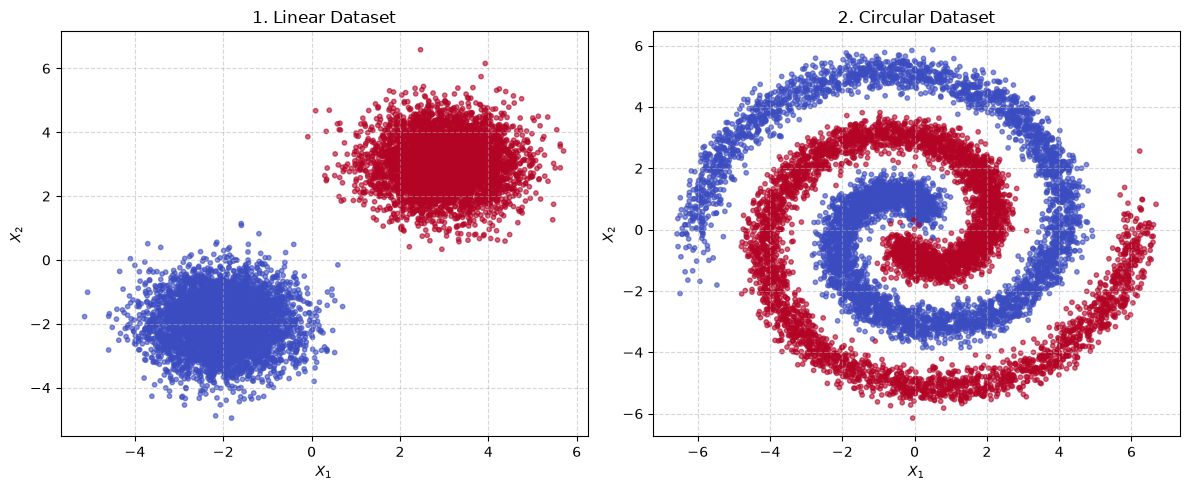

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Linear Dataset
axes[0].scatter(X_linear[:, 0], X_linear[:, 1], c=y_linear, cmap="coolwarm", alpha=0.6, s=10)
axes[0].set_title("1. Linear Dataset")
axes[0].set_xlabel("$X_1$")
axes[0].set_ylabel("$X_2$")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Plot 2: Circular Dataset
axes[1].scatter(X_circular[:, 0], X_circular[:, 1], c=y_circular, cmap="coolwarm", alpha=0.6, s=10)
axes[1].set_title("2. Circular Dataset")
axes[1].set_xlabel("$X_1$")
axes[1].set_ylabel("$X_2$")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# **2. SVM and perceptron comparison**

## Fit the models to the datasets

In [5]:
from sklearn.linear_model import Perceptron
from sklearn.svm import SVC

# Initialize models
perceptron_lin = Perceptron(random_state=42)
svm_lin = SVC(kernel='linear', random_state=42)

perceptron_circ = Perceptron(random_state=42)
svm_circ = SVC(kernel='linear', random_state=42)

# Train on Linear Dataset
perceptron_lin.fit(X_linear, y_linear)
svm_lin.fit(X_linear, y_linear)

# Train on Circular Dataset
perceptron_circ.fit(X_circular, y_circular)
svm_circ.fit(X_circular, y_circular) ;

## Plot each model's boundary for each dataset

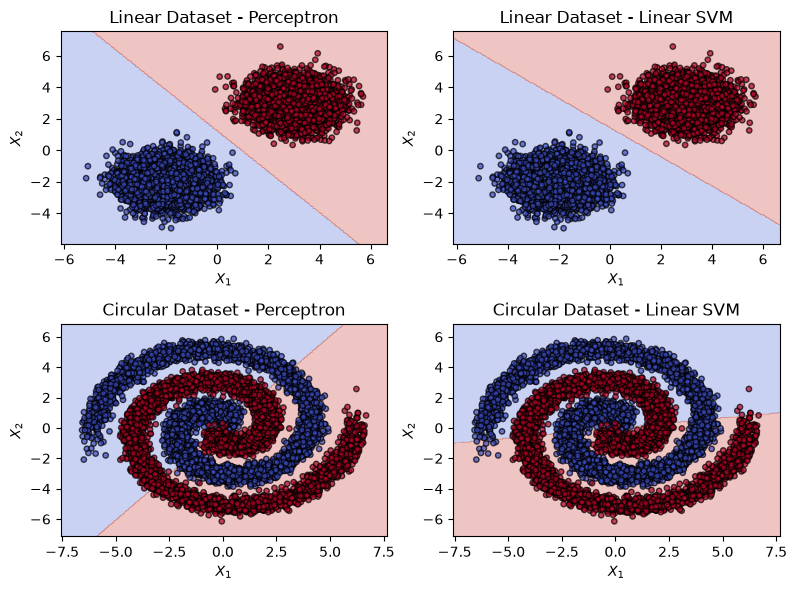

In [6]:
def plot_decision_boundary(ax, model, X, y, title):
    '''Plot the model's best separator by applying the model over a dense grid'''
    
    # Set min and max values and add some padding
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    
    # Create the plot grid
    grid_x, grid_y = np.meshgrid(
        np.arange(x_min, x_max, 0.05), 
        np.arange(y_min, y_max, 0.05)
    )
    preds = model.predict(np.c_[grid_x.ravel(), grid_y.ravel()]) # predict over 2D array
    preds = preds.reshape(grid_x.shape) # convert 1D output array to 2D for plotting
    
    ax.contourf(grid_x, grid_y, preds, alpha=0.3, cmap="coolwarm") # background color according to class
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor='k', s=15, alpha=0.7)
    ax.set_title(title)
    ax.set_xlabel("$X_1$")
    ax.set_ylabel("$X_2$")


# Plot the comparison (2x2 grid)
fig, axes = plt.subplots(2, 2, figsize=(8, 6))
plot_decision_boundary(axes[0, 0], perceptron_lin, X_linear, y_linear, "Linear Dataset - Perceptron")
plot_decision_boundary(axes[0, 1], svm_lin, X_linear, y_linear, "Linear Dataset - Linear SVM")
plot_decision_boundary(axes[1, 0], perceptron_circ, X_circular, y_circular, "Circular Dataset - Perceptron")
plot_decision_boundary(axes[1, 1], svm_circ, X_circular, y_circular, "Circular Dataset - Linear SVM")
plt.tight_layout()
plt.show()

# **3. SVM kernel**

--- RBF Kernel Performance ---
Accuracy: 0.9841
F1-score: 0.9841
Confusion Matrix:
 [[4930   70]
 [  89 4911]]

--- Polynomial Kernel Performance ---
Accuracy: 0.6899
F1-score: 0.6897
Confusion Matrix:
 [[3453 1547]
 [1554 3446]]


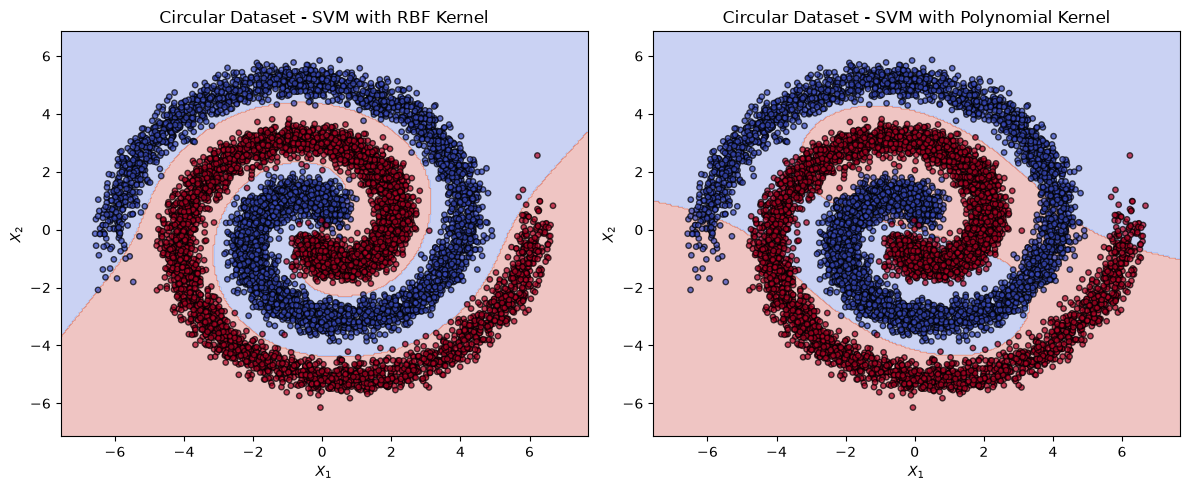

In [7]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

# Initialize models with RBF and Polynomial kernels for the circular dataset
svm_rbf = SVC(kernel='rbf', gamma='scale', random_state=42)
svm_poly = SVC(kernel='poly', degree=3, coef0=1, random_state=42)

# Train both models on the circular dataset
svm_rbf.fit(X_circular, y_circular)
svm_poly.fit(X_circular, y_circular)

# Predict and evaluate performance metrics
preds_rbf = svm_rbf.predict(X_circular)
preds_poly = svm_poly.predict(X_circular)

print("--- RBF Kernel Performance ---")
print(f"Accuracy: {accuracy_score(y_circular, preds_rbf):.4f}")
print(f"F1-score: {f1_score(y_circular, preds_rbf):.4f}")
print("Confusion Matrix:\n", confusion_matrix(y_circular, preds_rbf))

print("\n--- Polynomial Kernel Performance ---")
print(f"Accuracy: {accuracy_score(y_circular, preds_poly):.4f}")
print(f"F1-score: {f1_score(y_circular, preds_poly):.4f}")
print("Confusion Matrix:\n", confusion_matrix(y_circular, preds_poly))

# Plot the comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_decision_boundary(axes[0], svm_rbf, X_circular, y_circular, "Circular Dataset - SVM with RBF Kernel")
plot_decision_boundary(axes[1], svm_poly, X_circular, y_circular, "Circular Dataset - SVM with Polynomial Kernel")
plt.tight_layout()
plt.show()

# **4. Data augmentation**

Due to the high computational cost of performing 100,000 augmentation iterations, this part was executed separately on the university's computing server using a batched and parallelized NumPy implementation with Joblib.

The complete implementation is available in part4_augmentation.py.

The output plots are available in the cell below and in augmented_datasets.png.

The calculation was performed using 16 parallel workers and completed in approximately 7.1 minutes.

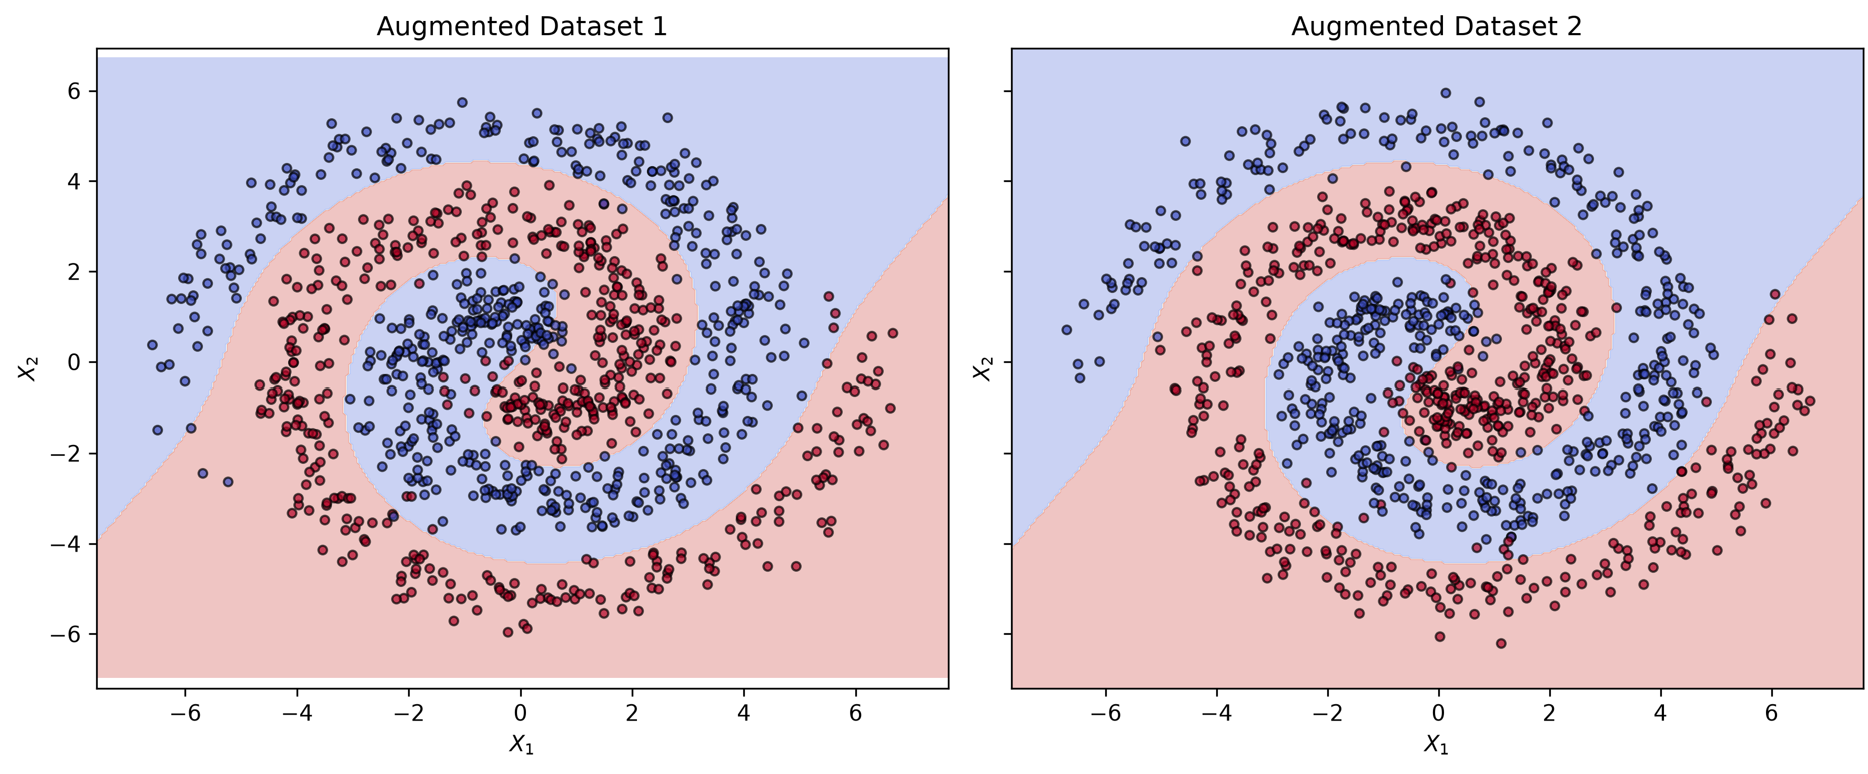

# **5. Noise analysis**

[LINEAR] Noise: 25.0%, Test Accuracy: 1.0000
[LINEAR] Noise: 40.0%, Test Accuracy: 1.0000
[LINEAR] Noise: 50.0%, Test Accuracy: 0.5060
[RBF] Noise: 25.0%, Test Accuracy: 0.9590
[RBF] Noise: 40.0%, Test Accuracy: 0.9250
[RBF] Noise: 50.0%, Test Accuracy: 0.4365


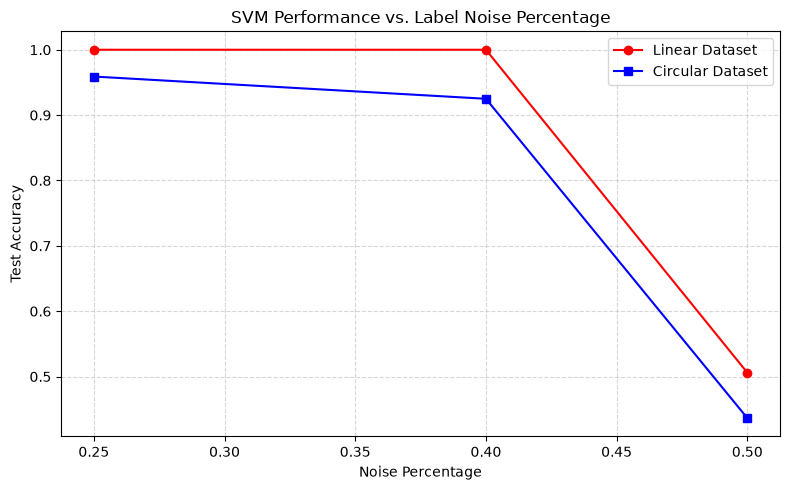

In [16]:
from sklearn.model_selection import train_test_split

np.random.seed(42)
noise_percent = [0.25, 0.40, 0.50]
accuracies_linear, accuracies_circular = [], []

datasets = [(X_linear, y_linear, 'linear', accuracies_linear),
    (X_circular, y_circular, 'rbf', accuracies_circular)]

for i, (X, y, kernel_type, acc_list) in enumerate(datasets):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    for percent in noise_percent:
        
        # Flip some indices to create label noise
        y_train_mix = y_train.copy()
        num_flip_indices = int(len(y_train_mix) * percent)
        indices_to_flip = np.random.choice(len(y_train_mix), size=num_flip_indices, replace=False)
        y_train_mix[indices_to_flip] = 1 - y_train_mix[indices_to_flip]

        # Train SVM and predict
        svm_mix = SVC(kernel=kernel_type, random_state=42)
        svm_mix.fit(X_train, y_train_mix)
        preds_mix = svm_mix.predict(X_test)
        acc = accuracy_score(y_test, preds_mix)
        acc_list.append(acc)
        print(f"[{kernel_type.upper()}] Noise: {percent * 100}%, Test Accuracy: {acc:.4f}")

# Plot the results
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(noise_percent, accuracies_linear, marker='o', linestyle='-', color='red', label='Linear Dataset')
ax.plot(noise_percent, accuracies_circular, marker='s', linestyle='-', color='blue', label='Circular Dataset')

ax.set_title("SVM Performance vs. Label Noise Percentage")
ax.set_xlabel("Noise Percentage")
ax.set_ylabel("Test Accuracy")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend()

plt.tight_layout()
plt.show()

# **6. High dimensionality**

## Generate high dimension datasets

In [22]:
def generate_high_dim_linear(d, n_half=5000):
    c0 = np.random.normal(loc=-2, scale=0.8, size=(n_half, d))
    c1 = np.random.normal(loc=3, scale=0.8, size=(n_half, d))
    X = np.vstack([c0, c1])
    y = np.array([0] * n_half + [1] * n_half)
    return X, y

def generate_high_dim_circular(d, n_half=5000):
    # Inner hypersphere (Class 0)
    v0 = np.random.normal(0, 1, size=(n_half, d))
    v0 /= np.linalg.norm(v0, axis=1, keepdims=True) # normalization
    r0 = np.random.normal(loc=1.5, scale=0.3, size=(n_half, 1))
    c0 = v0 * r0

    # Outer hypersphere (Class 1)
    v1 = np.random.normal(0, 1, size=(n_half, d))
    v1 /= np.linalg.norm(v1, axis=1, keepdims=True)
    r1 = np.random.normal(loc=4.0, scale=0.3, size=(n_half, 1))
    c1 = v1 * r1

    X = np.vstack([c0, c1])
    y = np.array([0] * n_half + [1] * n_half)
    return X, y

## Train and predict for high dimensions

In [23]:
np.random.seed(42)
dimensions = [2, 5, 10, 15] # 2D as reference
noise_levels = [0.0, 0.25, 0.40, 0.50]  # 0% (clean) vs. noise labels from Part 5
n = 10000
n_half = n // 2

# Store accuracy results: results[dataset_type][noise_level] = list of accuracies across dimensions
results = {
    "Linear (Linear Kernel)": {nl: [] for nl in noise_levels},
    "Circular (RBF Kernel)": {nl: [] for nl in noise_levels}
}

for d in dimensions:
    X_lin_d, y_lin_d = generate_high_dim_linear(d, n_half)
    X_circ_d, y_circ_d = generate_high_dim_circular(d, n_half)
    configs = [("Linear (Linear Kernel)", X_lin_d, y_lin_d, "linear"),
        ("Circular (RBF Kernel)", X_circ_d, y_circ_d, "rbf")]

    for name, X_d, y_d, kernel_type in configs:
        X_train, X_test, y_train, y_test = train_test_split(X_d, y_d, test_size=0.2, random_state=42)

        for nl in noise_levels:
            y_train_mix = y_train.copy()
            if nl > 0:
                num_flip = int(len(y_train_mix) * nl)
                flip_idx = np.random.choice(len(y_train_mix), size=num_flip, replace=False)
                y_train_mix[flip_idx] = 1 - y_train_mix[flip_idx]

            svm = SVC(kernel=kernel_type, gamma='scale', random_state=42)
            svm.fit(X_train, y_train_mix)
            preds = svm.predict(X_test)
            acc = accuracy_score(y_test, preds)
            results[name][nl].append(acc)
            print(f"Dim={d} | {name} | Noise={int(nl*100):2d}%, Test Acc: {acc:.4f}")
    print()

Dim=2 | Linear (Linear Kernel) | Noise= 0%, Test Acc: 1.0000
Dim=2 | Linear (Linear Kernel) | Noise=25%, Test Acc: 1.0000
Dim=2 | Linear (Linear Kernel) | Noise=40%, Test Acc: 1.0000
Dim=2 | Linear (Linear Kernel) | Noise=50%, Test Acc: 0.4940
Dim=2 | Circular (RBF Kernel) | Noise= 0%, Test Acc: 1.0000
Dim=2 | Circular (RBF Kernel) | Noise=25%, Test Acc: 1.0000
Dim=2 | Circular (RBF Kernel) | Noise=40%, Test Acc: 1.0000
Dim=2 | Circular (RBF Kernel) | Noise=50%, Test Acc: 0.5330

Dim=5 | Linear (Linear Kernel) | Noise= 0%, Test Acc: 1.0000
Dim=5 | Linear (Linear Kernel) | Noise=25%, Test Acc: 1.0000
Dim=5 | Linear (Linear Kernel) | Noise=40%, Test Acc: 1.0000
Dim=5 | Linear (Linear Kernel) | Noise=50%, Test Acc: 0.4780
Dim=5 | Circular (RBF Kernel) | Noise= 0%, Test Acc: 1.0000
Dim=5 | Circular (RBF Kernel) | Noise=25%, Test Acc: 1.0000
Dim=5 | Circular (RBF Kernel) | Noise=40%, Test Acc: 0.9775
Dim=5 | Circular (RBF Kernel) | Noise=50%, Test Acc: 0.4580

Dim=10 | Linear (Linear Kernel

## Plot Performance vs. Dimensionality

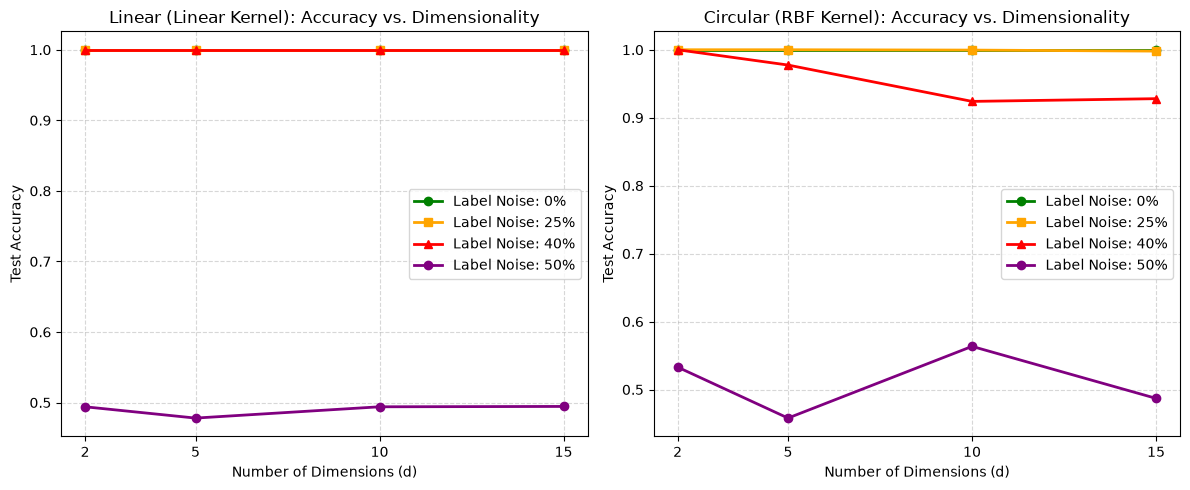

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
colors = {0.0: "green", 0.25: "orange", 0.40: "red", 0.50: "purple"}
markers = {0.0: "o", 0.25: "s", 0.40: "^", 0.50: "o"}

for idx, (name, noise_dict) in enumerate(results.items()):
    for nl, accs in noise_dict.items():
        axes[idx].plot(dimensions, accs, marker=markers[nl], linestyle='-', linewidth=2,
            color=colors[nl], label=f"Label Noise: {int(nl*100)}%")
    axes[idx].set_title(f"{name}: Accuracy vs. Dimensionality")
    axes[idx].set_xlabel("Number of Dimensions (d)")
    axes[idx].set_ylabel("Test Accuracy")
    axes[idx].set_xticks(dimensions)
    axes[idx].grid(True, linestyle="--", alpha=0.5)
    axes[idx].legend()

plt.tight_layout()
plt.show()